
# Data Preprocessing

## 1. Dataset Preparation

In this section, we prepare the datasets for the text preprocessing stage.

We load the raw datasets created from the Jigsaw Toxic Comment Classification Challenge.

The dataset consists of four CSV files:

1. **train.csv:** Contains comments and their six toxicity labels.
2. **test.csv:** Contains comments without target labels.
3. **test_labels.csv:** Contains the labels associated with the test comments.
4. **sample_submission.csv:** Provides the required submission format.

### Objectives

- Load all dataset files.
- Verify that the datasets are loaded correctly.
- Check their dimensions.
- Preserve the original raw data without modifications.

The loaded datasets will be used in the following preprocessing stages.



### 1.1 Importing Libraries

In this subsection, we import the Python libraries required for data preprocessing.

- **Pandas:** For loading and manipulating datasets.
- **NumPy:** For numerical operations.
- **Regular Expressions (re):** For text cleaning and pattern matching.

These libraries provide the basic tools needed to prepare the text data.


In [38]:
# Data Manipulation
import pandas as pd
import numpy as np

# Text Processing
import re

# Display Settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

print("All preprocessing libraries imported successfully!")

All preprocessing libraries imported successfully!



### 1.2 Loading Raw Datasets

In this subsection, we load the four CSV files from the raw data directory.

We use Pandas `read_csv()` to load each file into a DataFrame.

The original raw files will remain unchanged. All preprocessing operations will be performed on separate working DataFrames.


In [39]:
# Define Dataset Paths

train_path = "../data/raw/train.csv"
test_path = "../data/raw/test.csv"
test_labels_path = "../data/raw/test_labels.csv"
submission_path = "../data/raw/sample_submission.csv"


# Load Raw Datasets

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
test_labels_df = pd.read_csv(test_labels_path)
submission_df = pd.read_csv(submission_path)

print("All raw datasets loaded successfully!")

All raw datasets loaded successfully!



### 1.3 Dataset Dimensions Verification

In this subsection, we verify the dimensions of all loaded datasets.

We use the Pandas `shape` attribute to check the number of rows and columns in each DataFrame.

This verification ensures that the datasets were loaded correctly and their dimensions match the original dataset.


In [40]:
# Display Dataset Dimensions

datasets = {
    "Training Dataset": train_df,
    "Testing Dataset": test_df,
    "Test Labels": test_labels_df,
    "Submission Dataset": submission_df
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

Training Dataset: 159571 rows, 8 columns
Testing Dataset: 153164 rows, 2 columns
Test Labels: 153164 rows, 7 columns
Submission Dataset: 153164 rows, 7 columns



## 2. Creating Working Copies

In this section, we create separate working copies of the training and testing datasets.

The original raw datasets will remain unchanged throughout the preprocessing process.

All text cleaning and preprocessing operations will be applied to these working copies.

This approach helps preserve the original data and allows us to compare the processed data with the raw data when needed.


In [41]:
# Create Working Copies

train_processed = train_df.copy()
test_processed = test_df.copy()

# Verify Working Copies

print("Working copies created successfully!")

print("\nTraining Dataset Shape:", train_processed.shape)
print("Testing Dataset Shape:", test_processed.shape)

Working copies created successfully!

Training Dataset Shape: (159571, 8)
Testing Dataset Shape: (153164, 2)



## 3. Text Cleaning

In this section, we clean the comment text to prepare it for Natural Language Processing (NLP).

Raw comments may contain URLs, HTML tags, extra whitespace, and other text patterns that require handling.

Text cleaning helps reduce unnecessary noise while preserving the information needed for toxicity detection.

The cleaning process will be applied to the `comment_text` column in the training and testing working datasets.



### 3.2 Text Cleaning Function

In this subsection, we define a function to clean raw comments.

The cleaning function performs the following operations:

1. **HTML Removal:** Removes HTML tags from comments.
2. **URL Removal:** Removes web links.
3. **Lowercasing:** Converts all text to lowercase.
4. **Whitespace Cleaning:** Removes unnecessary spaces and line breaks.

We preserve punctuation, special characters, and negation words because they may contain useful information for toxicity detection.

The function will be tested on sample comments before applying it to the complete datasets.


In [42]:
# Define Updated Text Cleaning Function

def clean_text(text):

    # Handle missing or non-string values
    if not isinstance(text, str):
        return ""

    # Remove HTML tags
    text = re.sub(r"</?[\w][^>]*>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", " ", text)

    # Convert text to lowercase
    text = text.lower()

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [43]:
# Test Text Cleaning Function

sample_comments = [
    "HELLO WORLD!",
    "This is a <b>TOXIC</b> comment.",
    "Visit https://example.com for more information.",
    "You are NOT a good person!!!",
    "   This    comment has    extra spaces.   "
]

for comment in sample_comments:

    cleaned = clean_text(comment)

    print("Original:", comment)
    print("Cleaned :", cleaned)
    print("-" * 60)

Original: HELLO WORLD!
Cleaned : hello world!
------------------------------------------------------------
Original: This is a <b>TOXIC</b> comment.
Cleaned : this is a toxic comment.
------------------------------------------------------------
Original: Visit https://example.com for more information.
Cleaned : visit for more information.
------------------------------------------------------------
Original: You are NOT a good person!!!
Cleaned : you are not a good person!!!
------------------------------------------------------------
Original:    This    comment has    extra spaces.   
Cleaned : this comment has extra spaces.
------------------------------------------------------------



### 3.3 Applying Text Cleaning

In this subsection, we apply the `clean_text()` function to all comments in the training and testing datasets.

We use the Pandas `apply()` method to process each comment individually.

The cleaned comments are stored in a new column named `cleaned_text`, while the original `comment_text` column is preserved.

This allows us to compare the original and cleaned comments and maintain the original text for future reference.


In [44]:
# Apply Text Cleaning to Training Dataset

train_processed["cleaned_text"] = (
    train_processed["comment_text"].apply(clean_text)
)

# Apply Text Cleaning to Testing Dataset

test_processed["cleaned_text"] = (
    test_processed["comment_text"].apply(clean_text)
)

print("Text cleaning applied successfully!")

Text cleaning applied successfully!


In [45]:
# Verify Processed Dataset Shapes

print("Training Dataset Shape:", train_processed.shape)
print("Testing Dataset Shape:", test_processed.shape)

# Display Original and Cleaned Comments

display(
    train_processed[["comment_text", "cleaned_text"]].head()
)

Training Dataset Shape: (159571, 9)
Testing Dataset Shape: (153164, 3)


,comment_text,cleaned_text
0,"Explanation\nWhy the edits made under my username Hardcore Metallica Fan were reverted? They weren't vandalisms, just closure on some GAs after I ...","explanation why the edits made under my username hardcore metallica fan were reverted? they weren't vandalisms, just closure on some gas after i v..."
1,"D'aww! He matches this background colour I'm seemingly stuck with. Thanks. (talk) 21:51, January 11, 2016 (UTC)","d'aww! he matches this background colour i'm seemingly stuck with. thanks. (talk) 21:51, january 11, 2016 (utc)"
2,"Hey man, I'm really not trying to edit war. It's just that this guy is constantly removing relevant information and talking to me through edits in...","hey man, i'm really not trying to edit war. it's just that this guy is constantly removing relevant information and talking to me through edits in..."
3,"""\nMore\nI can't make any real suggestions on improvement - I wondered if the section statistics should be later on, or a subsection of """"types of...",""" more i can't make any real suggestions on improvement - i wondered if the section statistics should be later on, or a subsection of """"types of a..."
4,"You, sir, are my hero. Any chance you remember what page that's on?","you, sir, are my hero. any chance you remember what page that's on?"



### 3.4 Text Cleaning Verification

In this subsection, we verify the results of the text cleaning process.

We check:

1. Missing values in the cleaned text columns.
2. Empty comments after cleaning.
3. The data types of the cleaned text columns.

This verification helps ensure that the cleaned datasets are ready for the next preprocessing stages.


In [46]:
# Check Missing Values

print("Missing Values in Cleaned Text:")

print("Training:", train_processed["cleaned_text"].isnull().sum())
print("Testing:", test_processed["cleaned_text"].isnull().sum())


# Check Empty Comments

print("\nEmpty Comments After Cleaning:")

print("Training:", (train_processed["cleaned_text"].str.len() == 0).sum())
print("Testing:", (test_processed["cleaned_text"].str.len() == 0).sum())


# Check Data Types

print("\nCleaned Text Data Types:")

print("Training:", train_processed["cleaned_text"].dtype)
print("Testing:", test_processed["cleaned_text"].dtype)

Missing Values in Cleaned Text:
Training: 0
Testing: 0

Empty Comments After Cleaning:
Training: 7
Testing: 5

Cleaned Text Data Types:
Training: str
Testing: str



### 3.5 Inspecting Empty Comments

In this subsection, we inspect comments that became empty after text cleaning.

We display their original text and cleaned text to understand why they became empty.

This inspection helps us decide how to handle these records without losing potentially useful information.


In [47]:
# Inspect Empty Comments in Training Dataset

empty_train = train_processed[
    train_processed["cleaned_text"].str.len() == 0
]

display(empty_train[["comment_text", "cleaned_text"]])

,comment_text,cleaned_text
64904,http://en.wikipedia.org/wiki/Wikipedia_talk:No_original_research/archive15#YouTube_art_as_primary_source,
76037,http://finance.yahoo.com/news/7-fascinating-nuggets-another-bewildering-150348488.html,
94038,http://wikipediawehaveaproblem.com/evidence-of-cyberbullying-wp-editors-and-admins/ http://wikipediawehaveaproblem.com/evidence-of-cyberbullying-...,
106891,http://en.wikipedia.org/wiki/Wikipedia:ELYES,
123442,http://www.mediamonitors.net/edna47.html http://www.freerepublic.com/forum/a3ad7b207707d.htm,
141293,http://www.haaretz.com/news/diplomacy-defense/2-279-calories-per-person-how-israel-made-sure-gaza-didn-t-starve.premium-1.470419,
147665,http://www.world-pyramids.com/atr/usa/monkmound.html \nhttp://www.freewebs.com/historyofmonksmound/index.htm \nhttp://www.bibliotecapleyades.net/a...,


In [48]:
# Inspect Empty Comments in Testing Dataset

empty_test = test_processed[
    test_processed["cleaned_text"].str.len() == 0
]

display(empty_test[["comment_text", "cleaned_text"]])

,comment_text,cleaned_text
8938,http://en.wikipedia.org/wiki/Half-Life_%28series%29,
19464,http://www.google.ca/search?hl=en&source;=hp&q;=%22book+identifier%22+edu.ca&btnG;=Google+Search&meta;=cr%3DcountryCA&aq;=f&oq;=,
55142,,
103619,http://es.wikipedia.org/wiki/Usuario_Discusi%C3%B3n:Sarah_W.,
129243,http://en.wikipedia.org/wiki/Rayleigh%E2%80%93B%C3%A9nard_convection,


In [49]:
# Inspect Labels of Empty Training Comments

target_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

display(
    empty_train[
        ["id", "comment_text", "cleaned_text"] + target_columns
    ]
)

,id,comment_text,cleaned_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
64904,adac7518742a67c6,http://en.wikipedia.org/wiki/Wikipedia_talk:No_original_research/archive15#YouTube_art_as_primary_source,,0,0,0,0,0,0
76037,cb865a14eb50f867,http://finance.yahoo.com/news/7-fascinating-nuggets-another-bewildering-150348488.html,,0,0,0,0,0,0
94038,fb78de723a337228,http://wikipediawehaveaproblem.com/evidence-of-cyberbullying-wp-editors-and-admins/ http://wikipediawehaveaproblem.com/evidence-of-cyberbullying-...,,0,0,0,0,0,0
106891,3b9f582321af808c,http://en.wikipedia.org/wiki/Wikipedia:ELYES,,0,0,0,0,0,0
123442,9453c3fea5b96068,http://www.mediamonitors.net/edna47.html http://www.freerepublic.com/forum/a3ad7b207707d.htm,,0,0,0,0,0,0
141293,f3ea34b46e7bec23,http://www.haaretz.com/news/diplomacy-defense/2-279-calories-per-person-how-israel-made-sure-gaza-didn-t-starve.premium-1.470419,,0,0,0,0,0,0
147665,3ff4333a2976c327,http://www.world-pyramids.com/atr/usa/monkmound.html \nhttp://www.freewebs.com/historyofmonksmound/index.htm \nhttp://www.bibliotecapleyades.net/a...,,0,0,0,0,0,0



### 3.6 Final Text Cleaning Verification

In this subsection, we perform a final verification of the cleaned datasets.

We check the number of records, the number of empty comments, and the availability of the original and cleaned text columns.

This ensures that the datasets maintain their original structure and are ready for the next preprocessing stages.


In [50]:
# Final Dataset Verification

print("Training Dataset:")
print("Rows:", len(train_processed))
print("Empty Comments:", (train_processed["cleaned_text"].str.len() == 0).sum())

print("\nTesting Dataset:")
print("Rows:", len(test_processed))
print("Empty Comments:", (test_processed["cleaned_text"].str.len() == 0).sum())

print("\nColumn Verification:")
print("Training Columns:", train_processed.columns.tolist())
print("Testing Columns:", test_processed.columns.tolist())

Training Dataset:
Rows: 159571
Empty Comments: 7

Testing Dataset:
Rows: 153164
Empty Comments: 5

Column Verification:
Training Columns: ['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate', 'cleaned_text']
Testing Columns: ['id', 'comment_text', 'cleaned_text']



## 4. Text Preprocessing

In this section, we prepare the cleaned comments for Natural Language Processing (NLP) model development.

We analyze the cleaned text and apply appropriate preprocessing techniques while preserving important linguistic information.

The preprocessing steps will help transform raw comments into a format suitable for machine learning models.



### 4.1 Word Count Analysis

In this subsection, we calculate the number of words in each cleaned comment.

Word count analysis helps us understand the text length in terms of words rather than characters.

This information can help us understand the dataset and make informed decisions about tokenization and model input length.


In [51]:
# Calculate Word Count for Training Dataset

train_processed["word_count"] = (
    train_processed["cleaned_text"]
    .fillna("")
    .str.split()
    .str.len()
)

# Calculate Word Count for Testing Dataset

test_processed["word_count"] = (
    test_processed["cleaned_text"]
    .fillna("")
    .str.split()
    .str.len()
)

print("Word Count Calculated Successfully!")

Word Count Calculated Successfully!


In [52]:
# Display Word Count Statistics

print("Training Word Count Statistics:")
print(train_processed["word_count"].describe())

print("\nTesting Word Count Statistics:")
print(test_processed["word_count"].describe())

Training Word Count Statistics:
count    159571.000000
mean         67.228024
std          99.177544
min           0.000000
25%          17.000000
50%          36.000000
75%          75.000000
max        1411.000000
Name: word_count, dtype: float64

Testing Word Count Statistics:
count    153164.000000
mean         61.574423
std          98.921465
min           0.000000
25%          14.000000
50%          31.000000
75%          67.000000
max        2321.000000
Name: word_count, dtype: float64


In [53]:
# Display Sample Comments with Word Counts

display(
    train_processed[
        ["cleaned_text", "word_count"]
    ].head(10)
)

,cleaned_text,word_count
0,"explanation why the edits made under my username hardcore metallica fan were reverted? they weren't vandalisms, just closure on some gas after i v...",43
1,"d'aww! he matches this background colour i'm seemingly stuck with. thanks. (talk) 21:51, january 11, 2016 (utc)",17
2,"hey man, i'm really not trying to edit war. it's just that this guy is constantly removing relevant information and talking to me through edits in...",42
3,""" more i can't make any real suggestions on improvement - i wondered if the section statistics should be later on, or a subsection of """"types of a...",113
4,"you, sir, are my hero. any chance you remember what page that's on?",13
5,""" congratulations from me as well, use the tools well. · talk """,13
6,cocksucker before you piss around on my work,8
7,"your vandalism to the matt shirvington article has been reverted. please don't do it again, or you will be banned.",20
8,"sorry if the word 'nonsense' was offensive to you. anyway, i'm not intending to write anything in the article(wow they would jump on me for vandal...",83
9,alignment on this subject and which are contrary to those of dulithgow,12


### 4.2 Word Count Distribution

In this subsection, we visualize the distribution of word counts in the training dataset using a histogram.

The histogram helps us understand:

- The most common comment lengths.
- How frequently short and long comments occur.
- Whether the distribution is right-skewed.
- The presence of unusually long comments.

This analysis helps us understand text length variation before model training.

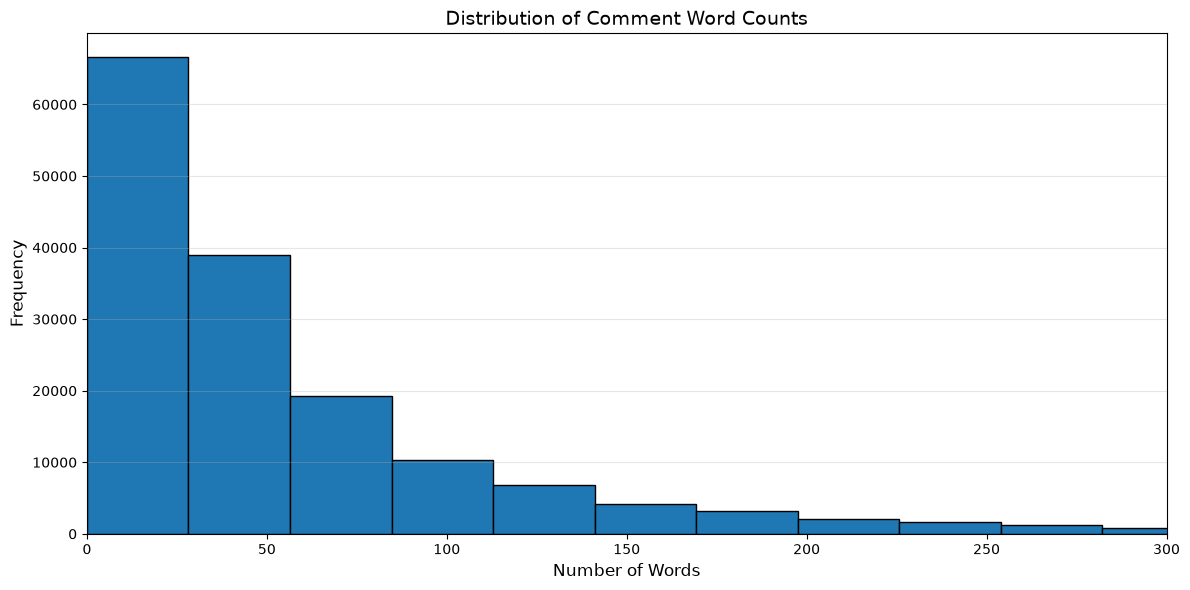

In [58]:
# Plot Word Count Distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.hist(
    train_processed["word_count"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Comment Word Counts", fontsize=14)
plt.xlabel("Number of Words", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.xlim(0, 300)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 4.3 Average Word Count by Toxicity

In this subsection, we compare the average number of words in toxic and non-toxic comments.

We group comments according to the general `toxic` label:

- **Non-Toxic (0):** Comments without the general toxicity label.
- **Toxic (1):** Comments with the general toxicity label.

We calculate the average word count for each group and visualize the results using a bar chart.

This analysis helps us investigate whether toxic comments tend to be longer or shorter than non-toxic comments.

Average Word Count by Toxicity:
toxic
0    68.919551
1    51.270891
Name: word_count, dtype: float64


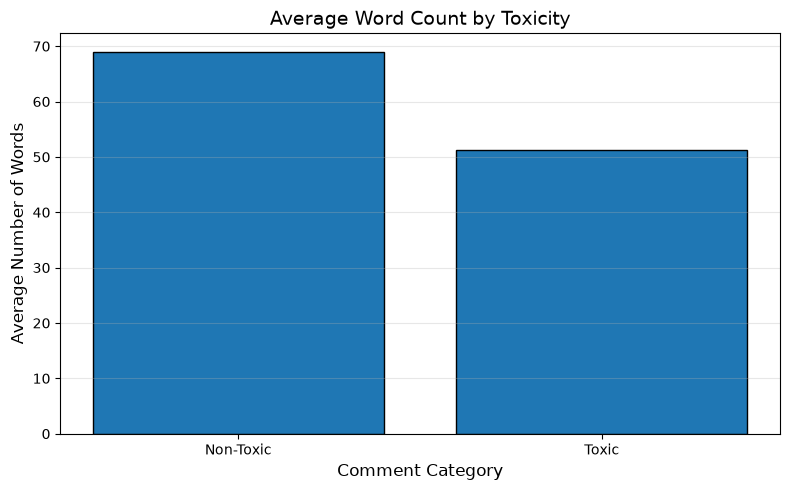

In [59]:
# Calculate Average Word Count by Toxicity

avg_word_count = train_processed.groupby("toxic")["word_count"].mean()

print("Average Word Count by Toxicity:")
print(avg_word_count)

# Plot Average Word Count

plt.figure(figsize=(8, 5))

plt.bar(
    ["Non-Toxic", "Toxic"],
    avg_word_count.values,
    edgecolor="black"
)

plt.title("Average Word Count by Toxicity", fontsize=14)
plt.xlabel("Comment Category", fontsize=12)
plt.ylabel("Average Number of Words", fontsize=12)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 4.4 Preprocessing Summary

In this subsection, we summarize the main findings from the text preprocessing stage.

We review:

1. The number of records in the training and testing datasets.
2. The number of empty comments after cleaning.
3. The average and median word counts.
4. The average word count for toxic and non-toxic comments.

This summary helps us document the preprocessing results and understand the characteristics of the cleaned text data before model development.

In [60]:
# Generate Preprocessing Summary

preprocessing_summary = pd.DataFrame({
    "Metric": [
        "Training Records",
        "Testing Records",
        "Empty Training Comments",
        "Empty Testing Comments",
        "Average Training Word Count",
        "Median Training Word Count",
        "Average Non-Toxic Word Count",
        "Average Toxic Word Count"
    ],
    "Value": [
        len(train_processed),
        len(test_processed),
        (train_processed["cleaned_text"].str.len() == 0).sum(),
        (test_processed["cleaned_text"].str.len() == 0).sum(),
        round(train_processed["word_count"].mean(), 2),
        train_processed["word_count"].median(),
        round(avg_word_count.loc[0], 2),
        round(avg_word_count.loc[1], 2)
    ]
})

display(preprocessing_summary)

,Metric,Value
0,Training Records,159571.00
1,Testing Records,153164.00
2,Empty Training Comments,7.00
3,Empty Testing Comments,5.00
4,Average Training Word Count,67.23
5,Median Training Word Count,36.00
6,Average Non-Toxic Word Count,68.92
7,Average Toxic Word Count,51.27


## 5. Preparing Data for Model Training

In this section, we prepare the cleaned datasets for machine learning model development.

The preparation process includes:

1. Handling empty comments.
2. Separating text features from target labels.
3. Splitting the training data into training and validation sets.
4. Preparing the testing data for final predictions.

The project uses Multi-Label Classification with six toxicity labels.

### 5.1 Handling Empty Comments

In this subsection, we handle comments that became empty after text cleaning.

Empty comments do not contain useful textual information for model training.

We remove empty comments from the training dataset while preserving all testing records to maintain the original testing dataset size.

The original raw datasets remain unchanged.

In [61]:
# Count Empty Comments Before Handling

empty_train_count = (
    train_processed["cleaned_text"].str.strip().eq("").sum()
)

empty_test_count = (
    test_processed["cleaned_text"].str.strip().eq("").sum()
)

print("Empty Training Comments:", empty_train_count)
print("Empty Testing Comments:", empty_test_count)


# Remove Empty Comments from Training Dataset

train_processed = train_processed[
    train_processed["cleaned_text"].str.strip().ne("")
].copy()


# Verify Dataset Sizes

print("\nAfter Handling Empty Comments:")
print("Training Dataset Shape:", train_processed.shape)
print("Testing Dataset Shape:", test_processed.shape)

Empty Training Comments: 7
Empty Testing Comments: 5

After Handling Empty Comments:
Training Dataset Shape: (159564, 10)
Testing Dataset Shape: (153164, 4)


### 5.2 Separating Features and Target Labels

In this subsection, we separate the input text features from the target labels.

The input features consist of the cleaned comments stored in the `cleaned_text` column.

The target labels consist of six toxicity categories:

- toxic
- severe_toxic
- obscene
- threat
- insult
- identity_hate

Since a comment can belong to multiple toxicity categories, this project is treated as a Multi-Label Classification problem.

In [62]:
# Define Target Labels

target_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

# Separate Features and Target Labels

X = train_processed["cleaned_text"]

y = train_processed[target_columns]

# Prepare Testing Features

X_test = test_processed["cleaned_text"]

# Verify Data Shapes

print("Training Features Shape:", X.shape)
print("Training Labels Shape:", y.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTarget Labels:")
print(y.columns.tolist())

Training Features Shape: (159564,)
Training Labels Shape: (159564, 6)
Testing Features Shape: (153164,)

Target Labels:
['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


### 5.3 Splitting Training and Validation Data

In this subsection, we split the training dataset into training and validation sets.

The dataset is divided into two parts:

- **Training Set (80%):** Used to train the machine learning models.
- **Validation Set (20%):** Used to evaluate model performance during development.

We use `train_test_split()` from Scikit-learn with a fixed random state to ensure reproducibility.

The same split will be used when comparing different models.

In [63]:
# Import Train-Test Split

from sklearn.model_selection import train_test_split

# Split Training Data

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display Dataset Shapes

print("Training Features:", X_train.shape)
print("Validation Features:", X_val.shape)

print("\nTraining Labels:", y_train.shape)
print("Validation Labels:", y_val.shape)

Training Features: (127651,)
Validation Features: (31913,)

Training Labels: (127651, 6)
Validation Labels: (31913, 6)


### 5.4 Verifying Label Distribution

In this subsection, we compare the distribution of the six target labels across the training and validation sets.

This verification helps us determine whether both sets contain similar proportions of positive and negative samples.

Maintaining comparable label distributions is important for reliable model evaluation.

In [64]:
# Calculate Positive Label Percentages

train_label_distribution = y_train.mean() * 100
val_label_distribution = y_val.mean() * 100

# Create Comparison DataFrame

label_comparison = pd.DataFrame({
    "Training (%)": train_label_distribution,
    "Validation (%)": val_label_distribution
})

label_comparison["Difference (%)"] = (
    label_comparison["Training (%)"] -
    label_comparison["Validation (%)"]
).abs()

# Display Results

display(label_comparison.round(2))

,Training (%),Validation (%),Difference (%)
toxic,9.61,9.47,0.14
severe_toxic,1.01,0.97,0.04
obscene,5.31,5.24,0.07
threat,0.30,0.32,0.02
insult,4.94,4.92,0.02
identity_hate,0.86,0.94,0.08


### 5.5 Preparing Data for TF-IDF Vectorization

In this subsection, we prepare the text data for numerical representation using TF-IDF.

Machine learning algorithms cannot directly process raw text. Therefore, we need to convert comments into numerical feature vectors.

Before applying TF-IDF, we verify that the training and validation text data are ready.

The TF-IDF vectorizer will be fitted on the training data only and then used to transform the validation and testing data.

In [65]:
# Verify Text Data

print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

print("\nMissing Values:")
print("Training:", X_train.isnull().sum())
print("Validation:", X_val.isnull().sum())
print("Testing:", X_test.isnull().sum())

print("\nSample Training Comments:")
display(X_train.head())

Training Samples: 127651
Validation Samples: 31913
Testing Samples: 153164

Missing Values:
Training: 0
Validation: 0
Testing: 0

Sample Training Comments:


2874      editing/deleting hi, im user:cj2005b. i dont go round trying to make enemys with anyone! all i asked is that you and other wikipedia users be fair...
32575                                              (utc) it comes from the seventh layer of hell and thats where it should stay, gross! 18:19, 9 september 2006
74662     " fyi noticed the message ""access denied for user 'tparis'@'%.toolserver.org' to database 'u_soxred93'"" at the top of the results when i checked...
89432                                                                                                     panathinaikos.they tend to sit on the couch and watch
114569    i am a professional journalist. if you continue to revert my post on john mccain, i will report on the fact that upon tracing your ip address 152....
Name: cleaned_text, dtype: str

### 5.6 TF-IDF Vectorization

In this subsection, we convert the cleaned text comments into numerical feature vectors using TF-IDF (Term Frequency-Inverse Document Frequency).

TF-IDF measures the importance of words in a document relative to the entire collection of documents.

We use the following configuration:

- **max_features = 50000:** Limits the vocabulary to the 50,000 most relevant features.
- **ngram_range = (1, 2):** Considers individual words and pairs of consecutive words.
- **min_df = 2:** Ignores terms that appear in fewer than two documents.
- **max_df = 0.95:** Ignores terms appearing in more than 95% of documents.

The vectorizer is fitted only on the training data to prevent data leakage. The same fitted vectorizer is then used to transform the validation and testing data.

In [69]:
# Import TF-IDF Vectorizer

from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Fit on Training Data and Transform

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

print("TF-IDF Vectorization Completed!")
print("Training TF-IDF Shape:", X_train_tfidf.shape)



TF-IDF Vectorization Completed!
Training TF-IDF Shape: (127651, 50000)


In [70]:
# Transform Validation Data
 
X_val_tfidf = tfidf_vectorizer.transform(X_val)

# Transform Testing Data

X_test_tfidf = tfidf_vectorizer.transform(X_test)

# Verify TF-IDF Shapes

print("Validation TF-IDF Shape:", X_val_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Validation TF-IDF Shape: (31913, 50000)
Testing TF-IDF Shape: (153164, 50000)


### 5.7 Final Data Preparation Verification

In this subsection, we perform a final verification of the prepared datasets before model training.

We check:

1. The dimensions of the TF-IDF feature matrices.
2. The dimensions of the target label matrices.
3. The data types of the feature matrices.
4. Whether the TF-IDF matrices are sparse matrices.

This verification ensures that the datasets are correctly prepared for machine learning model training.

In [71]:
# Import Sparse Matrix Checker

from scipy.sparse import issparse

# Verify Feature Shapes

print("Training Features:", X_train_tfidf.shape)
print("Validation Features:", X_val_tfidf.shape)
print("Testing Features:", X_test_tfidf.shape)

# Verify Target Shapes

print("\nTraining Labels:", y_train.shape)
print("Validation Labels:", y_val.shape)

# Verify Data Types

print("\nFeature Matrix Type:", type(X_train_tfidf))
print("Is Training Matrix Sparse:", issparse(X_train_tfidf))
print("Is Validation Matrix Sparse:", issparse(X_val_tfidf))
print("Is Testing Matrix Sparse:", issparse(X_test_tfidf))

Training Features: (127651, 50000)
Validation Features: (31913, 50000)
Testing Features: (153164, 50000)

Training Labels: (127651, 6)
Validation Labels: (31913, 6)

Feature Matrix Type: <class 'scipy.sparse._csr.csr_matrix'>
Is Training Matrix Sparse: True
Is Validation Matrix Sparse: True
Is Testing Matrix Sparse: True


### 6. Saving Processed Datasets

In this section, we save the cleaned training and testing datasets
to the processed data directory.

The original raw datasets remain unchanged.

These processed files will be reused in the following machine learning stages.

In [72]:
import os

# Create Processed Data Directory
os.makedirs("../data/processed", exist_ok=True)

# Save Cleaned Datasets
train_processed.to_csv(
    "../data/processed/train_processed.csv",
    index=False
)

test_processed.to_csv(
    "../data/processed/test_processed.csv",
    index=False
)

print("Processed datasets saved successfully!")

Processed datasets saved successfully!


In [73]:
print(os.listdir("../data/processed"))

['test_processed.csv', 'train_processed.csv']


### 7. Saving TF-IDF Feature Matrices

In this section, we save the TF-IDF feature matrices for training,
validation, and testing datasets.

We use the SciPy sparse matrix format to preserve memory efficiency.

The saved matrices can be loaded later without repeating the vectorization process.

In [74]:
from scipy.sparse import save_npz

# Save TF-IDF Matrices
save_npz("../data/processed/X_train_tfidf.npz", X_train_tfidf)
save_npz("../data/processed/X_val_tfidf.npz", X_val_tfidf)
save_npz("../data/processed/X_test_tfidf.npz", X_test_tfidf)

print("TF-IDF matrices saved successfully!")

TF-IDF matrices saved successfully!


In [75]:
print(os.listdir("../data/processed"))

['test_processed.csv', 'train_processed.csv', 'X_test_tfidf.npz', 'X_train_tfidf.npz', 'X_val_tfidf.npz']


### 8. Saving Target Labels

In this section, we save the target labels for the training and validation datasets.

These labels correspond to the six toxicity categories and will be used during model training and evaluation.

In [76]:
# Save Training and Validation Labels

y_train.to_csv(
    "../data/processed/y_train.csv",
    index=False
)

y_val.to_csv(
    "../data/processed/y_val.csv",
    index=False
)

print("Target labels saved successfully!")

Target labels saved successfully!


In [77]:
print(os.listdir("../data/processed"))

['test_processed.csv', 'train_processed.csv', 'X_test_tfidf.npz', 'X_train_tfidf.npz', 'X_val_tfidf.npz', 'y_train.csv', 'y_val.csv']


### 9. Final Processed Data Verification

In this section, we reload the saved processed datasets and TF-IDF matrices.

We verify that all files are accessible and their dimensions match the expected training, validation, and testing data.

This ensures that the processed data is ready for machine learning model development.

In [78]:
from scipy.sparse import load_npz

# Load Saved TF-IDF Matrices
X_train_check = load_npz("../data/processed/X_train_tfidf.npz")
X_val_check = load_npz("../data/processed/X_val_tfidf.npz")
X_test_check = load_npz("../data/processed/X_test_tfidf.npz")

# Load Saved Target Labels
y_train_check = pd.read_csv("../data/processed/y_train.csv")
y_val_check = pd.read_csv("../data/processed/y_val.csv")

# Verify Shapes
print("Training Features:", X_train_check.shape)
print("Training Labels:", y_train_check.shape)

print("\nValidation Features:", X_val_check.shape)
print("Validation Labels:", y_val_check.shape)

print("\nTesting Features:", X_test_check.shape)

print("\nAll processed data files loaded successfully!")

Training Features: (127651, 50000)
Training Labels: (127651, 6)

Validation Features: (31913, 50000)
Validation Labels: (31913, 6)

Testing Features: (153164, 50000)

All processed data files loaded successfully!
